# Synthetic data

What part of a series is predictable? Build a controlled process, inspect its components, then ask a forecaster to predict a genuinely unseen future.

**Development notebook.** Expand the library cells to edit the implementation. Examples below use local data and CPU. [Build workflow](README.md#develop-the-package-here).

In [1]:
#| default_exp scenarios

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
plt.style.use('default')
plt.rcParams.update({'figure.figsize': (12, 4), 'figure.dpi': 110,
    'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': False, 'legend.frameon': False, 'axes.titlelocation': 'left'})

## Build `scenarios`

### Imports and configuration

In [3]:
#| export scenarios
from __future__ import annotations

from dataclasses import dataclass, field
from typing import Any

import numpy as np
import pandas as pd

from timegym.contracts import Case, ForecastTask, Reference, MANIFEST_SCHEMA_VERSION
from timegym._internal import _real_array
from timegym.processes import PROCESS_KINDS, resolve_process, _generate_resolved_process, process_label

__all__ = ["Case", "CORE_KINDS", "scenario_label", "Scenario"]


### Case — One held-out forecast task and its evaluator-only ground truth.

In [4]:
#| export scenarios
_DEFAULTS = {
    "white_noise": {"mean": 0.0, "sigma": 1.0},
    "trend": {"intercept": 0.0, "slope": 0.1, "sigma": 1.0},
    "seasonal": {"mean": 0.0, "amplitude": 1.0, "period": 12.0, "sigma": 1.0},
    "ar1": {"mean": 0.0, "phi": 0.8, "sigma": 1.0},
    "random_walk": {"intercept": 0.0, "drift": 0.0, "sigma": 1.0},
    "ar2": {"mean": 0.0, "phi1": 1.0, "phi2": -0.5, "sigma": 1.0},
}

# The five families of the original suite; ``default_scenarios`` draws these.
CORE_KINDS = ("white_noise", "trend", "seasonal", "ar1", "random_walk")
# Families whose shocks persist. They also accept optional measurement
# ``noise``: independent Gaussian error added to each observation, which
# hides the process's current state from the forecaster.
_MEASURED_KINDS = ("ar1", "ar2", "random_walk")
_SCALAR_PARAMETERS = {"phi", "phi1", "phi2", "period"}

### Shared positive integer validation

In [5]:
#| export scenarios
from timegym._internal import positive_int

### Shared seed validation

In [6]:
#| export scenarios
from timegym._internal import nonnegative_int

### Human-readable process labels

Keep kind identifiers stable; make drift explicit in figures and descriptions.

In [7]:
#| export scenarios
def scenario_label(kind: str, parameters=None, *, target_index=None) -> str:
    """Describe a process without replacing its stable machine-readable kind.

    Parameters may be raw scalar/vector values or a resolved case manifest's
    parameter dictionary. A target index selects its drift for a plot facet;
    otherwise a mixed zero/nonzero drift vector is described at case level.
    Nonzero measurement ``noise`` is named in the label. This formats labels
    rather than validating a full generator specification. Unknown custom
    kinds are returned unchanged.
    """
    if kind in PROCESS_KINDS:
        return process_label(kind, {} if parameters is None else parameters, target_index=target_index)
    parameters = {} if parameters is None else parameters
    labels = {
        "white_noise": "Gaussian white noise (fixed mean)",
        "trend": "Linear trend + white noise",
        "seasonal": "Seasonality + white noise",
        "ar1": "Stationary AR(1)",
        "ar2": "Stationary AR(2)",
    }
    if kind == "random_walk":
        drift = _real_array(parameters.get("drift", 0.0), "drift")
        if drift.ndim > 1 or drift.size == 0 or not np.isfinite(drift).all():
            raise ValueError("drift must be a finite scalar or a nonempty vector")
        if target_index is not None:
            target_index = nonnegative_int(target_index, 'target_index')
            if drift.ndim == 1:
                drift = drift[target_index]
        nonzero = drift != 0
        if not np.any(nonzero):
            label = "Random walk without drift"
        elif np.all(nonzero):
            label = "Random walk with drift"
        else:
            label = "Random walk (mixed drift across targets)"
    else:
        label = labels.get(kind, kind)
    if kind in _MEASURED_KINDS and np.any(np.asarray(parameters.get("noise", 0.0), dtype=float) != 0):
        label += " + measurement noise"
    return label

### Hidden states seen through noise

A random walk or an autoregressive process carries its shocks forward, so the
best forecast starts from where the process *is* now. With measurement noise
on top, that current state is hidden: each observation is the state plus a
fresh error. The best a forecaster can do is weigh the noisy history, which is
exactly what the Kalman filter computes for these linear Gaussian processes.
With known parameters it gives the exact conditional mean and covariance of
the future observations, so these cases keep an exact answer key.

In [8]:
#| export scenarios
def _kalman_forecast(observations, transition, offset, innovation, measurement,
                     initial_mean, initial_covariance, horizon):
    """Exact Gaussian forecast for a linear state observed with noise.

    The state follows ``s_t = offset + transition @ s_{t-1} + shock`` and each
    observation is the state's first ``d`` entries plus measurement error.
    Returns the conditional mean ``(horizon, d)``, the horizon-major joint
    covariance ``(horizon*d, horizon*d)`` and the final filtered state mean.
    The Joseph-form update with a pseudo-inverse stays valid when an
    observation is noise-free.
    """
    length, dimensions = observations.shape
    size = len(offset)
    loading = np.eye(dimensions, size)
    mean, cov = initial_mean.copy(), initial_covariance.copy()
    for t in range(length):
        if t:
            mean = offset + transition @ mean
            cov = transition @ cov @ transition.T + innovation
        gain = cov @ loading.T @ np.linalg.pinv(loading @ cov @ loading.T + measurement, hermitian=True)
        mean = mean + gain @ (observations[t] - loading @ mean)
        keep = np.eye(size) - gain @ loading
        cov = keep @ cov @ keep.T + gain @ measurement @ gain.T
        cov = (cov + cov.T) / 2
    filtered = mean.copy()
    means, state_covs = [], []
    for _ in range(horizon):
        mean = offset + transition @ mean
        cov = transition @ cov @ transition.T + innovation
        means.append(loading @ mean)
        state_covs.append(cov)
    joint = np.zeros((horizon * dimensions, horizon * dimensions))
    for i in range(horizon):
        cross = state_covs[i]
        for j in range(i, horizon):
            block = loading @ cross @ loading.T + (measurement if i == j else 0)
            joint[i * dimensions:(i + 1) * dimensions, j * dimensions:(j + 1) * dimensions] = block
            joint[j * dimensions:(j + 1) * dimensions, i * dimensions:(i + 1) * dimensions] = block.T
            cross = cross @ transition.T
    return np.array(means), (joint + joint.T) / 2, filtered

### Scenario — A fully specified known-parameter Gaussian data-generating process.

In [9]:
#| export scenarios
@dataclass
class Scenario:
    """A fully specified known-parameter data-generating process.

    Vector-valued location/scale parameters are allowed, with one entry per
    target. ``phi``, ``phi1``, ``phi2`` and ``period`` are scalar.
    ``correlation`` is either an equicorrelation coefficient or a
    positive-semidefinite correlation matrix.

    AR(1) starts from its stationary distribution and requires ``abs(phi)<1``.
    AR(2) uses two lags, ``phi1`` and ``phi2``; with ``phi1**2 + 4*phi2 < 0``
    its shocks ring as irregular cycles. It also starts stationary.
    White noise fluctuates around a fixed mean; trend and seasonal processes
    add noise independently over time to a deterministic mean. Those shocks
    do not carry into future observations. A random walk instead accumulates
    shocks, starts at ``intercept`` at index zero, and has optional ``drift``
    (zero by default). Its variance grows with the forecast horizon. Targets
    may have correlated contemporaneous innovations in every family. Zero
    ``sigma`` gives a degenerate deterministic component. AR(1), AR(2) and
    random walks accept an optional measurement ``noise``: an independent
    Gaussian error with that standard deviation is added to each
    observation, so the process's current state is hidden; the reference is
    then the exact Kalman-filter conditional law. Parameters are exposed
    to the evaluator only; a model receives just ``case.task``. The
    composite, Merton, GARCH and hidden-regime processes also support joint
    targets, with explicit dependence laws and reference capabilities. These
    four controlled families snapshot resolved parameters at construction;
    create a new Scenario to change their parameters.
    """

    kind: str
    context_length: int = 120
    horizon: int = 12
    parameters: dict[str, Any] = field(default_factory=dict)
    n_targets: int = 1
    seed: int = 0

    def __post_init__(self) -> None:
        if self.kind in PROCESS_KINDS:
            self._resolved_parameters = self._resolve_process()
        else:
            self._resolve()

    def _resolve_process(self):
        return resolve_process(self.kind, self.parameters, self.context_length,
                               self.horizon, self.n_targets, self.seed)

    @property
    def display_name(self) -> str:
        """Parameter-aware label; ``kind`` remains the stable scenario identifier."""
        if self.kind in PROCESS_KINDS:
            return process_label(self.kind, self._resolved_parameters)
        parameters, _, _, _, _ = self._resolve()
        return scenario_label(self.kind, parameters)

    def _resolve(self) -> tuple[dict, np.ndarray, int, int, int]:
        if self.kind not in _DEFAULTS:
            raise ValueError(f"Unknown scenario {self.kind!r}; choose from {tuple(_DEFAULTS)}")
        length = positive_int(self.context_length, 'context_length')
        horizon = positive_int(self.horizon, 'horizon')
        dimensions = positive_int(self.n_targets, 'n_targets')
        nonnegative_int(self.seed, 'seed')
        if not isinstance(self.parameters, dict):
            raise TypeError("parameters must be a dictionary")
        optional = {"correlation"} | ({"noise"} if self.kind in _MEASURED_KINDS else set())
        unsupported = set(self.parameters) - set(_DEFAULTS[self.kind]) - optional
        if unsupported:
            raise ValueError(f"Unsupported parameters for {self.kind}: {sorted(unsupported)}")
        parameters = {**_DEFAULTS[self.kind], **self.parameters}
        correlation = _real_array(parameters.pop("correlation", 0.0), "correlation")
        if correlation.ndim == 0:
            rho = float(correlation)
            lower = -1.0 / (dimensions - 1) if dimensions > 1 else -1.0
            if not np.isfinite(rho) or not lower <= rho <= 1.0:
                raise ValueError(f"Scalar correlation must be between {lower} and 1")
            correlation = np.full((dimensions, dimensions), rho)
            np.fill_diagonal(correlation, 1.0)
        if correlation.shape != (dimensions, dimensions) or not np.isfinite(correlation).all():
            raise ValueError("correlation must have shape (n_targets, n_targets) and finite entries")
        if not np.allclose(correlation, correlation.T, atol=1e-12, rtol=1e-10):
            raise ValueError("correlation must be symmetric")
        if not np.allclose(np.diag(correlation), 1.0, atol=1e-12, rtol=1e-10) or np.linalg.eigvalsh(correlation).min() < -1e-10:
            raise ValueError("correlation must have unit diagonal and be positive semidefinite")
        resolved: dict[str, Any] = {}
        for name, raw in parameters.items():
            value = _real_array(raw, name)
            if not np.isfinite(value).all():
                raise ValueError(f"{name} must be finite")
            if name in _SCALAR_PARAMETERS:
                if value.ndim != 0:
                    raise ValueError(f"{name} must be scalar")
                resolved[name] = float(value)
            else:
                if value.ndim == 0:
                    value = np.full(dimensions, float(value))
                if value.shape != (dimensions,):
                    raise ValueError(f"{name} must be scalar or have one entry per target")
                resolved[name] = value
        if np.any(resolved["sigma"] < 0):
            raise ValueError("sigma must be nonnegative")
        if "noise" in resolved and np.any(resolved["noise"] < 0):
            raise ValueError("noise must be nonnegative")
        if self.kind == "ar2":
            phi1, phi2 = resolved["phi1"], resolved["phi2"]
            if not (phi1 + phi2 < 1 and phi2 - phi1 < 1 and abs(phi2) < 1):
                raise ValueError("Stationary ar2 requires phi1 + phi2 < 1, phi2 - phi1 < 1 and abs(phi2) < 1")
        if "phi" in resolved and not abs(resolved["phi"]) < 1:
            raise ValueError("Stationary ar1 requires abs(phi) < 1")
        if "period" in resolved and resolved["period"] <= 0:
            raise ValueError("period must be positive")
        return resolved, correlation, length, horizon, dimensions

    def generate(self, seed: int | None = None) -> Case:
        """Generate context and held-out observations without global RNG state."""
        if self.kind in PROCESS_KINDS:
            run_seed = nonnegative_int(self.seed if seed is None else seed, 'seed')
            return _generate_resolved_process(self.kind, self._resolved_parameters, self.context_length,
                                    self.horizon, self.n_targets, run_seed)
        p, correlation, length, horizon, dimensions = self._resolve()
        run_seed = nonnegative_int(self.seed if seed is None else seed, 'seed')
        rng = np.random.default_rng(run_seed)
        innovation_cov = correlation * np.outer(p["sigma"], p["sigma"])
        eigenvalues, eigenvectors = np.linalg.eigh(innovation_cov)
        factor = eigenvectors * np.sqrt(np.maximum(eigenvalues, 0.0))
        noise = rng.standard_normal((length + horizon, dimensions)) @ factor.T
        time = np.arange(length + horizon, dtype=float)[:, None]
        future_steps = np.arange(1, horizon + 1, dtype=float)[:, None]
        temporal_cov = np.eye(horizon)
        conditioning: dict[str, Any] = {
            "observed_through": length - 1,
            "known_generator_parameters": True,
            "future_observations_used": False,
        }

        if self.kind == "white_noise":
            signal = np.broadcast_to(p["mean"], noise.shape)
            values = signal + noise
            conditional_mean = signal[length:].copy()
        elif self.kind == "trend":
            signal = p["intercept"] + p["slope"] * time
            values = signal + noise
            conditional_mean = signal[length:].copy()
        elif self.kind == "seasonal":
            signal = p["mean"] + p["amplitude"] * np.sin(2 * np.pi * time / p["period"])
            values = signal + noise
            conditional_mean = signal[length:].copy()
        elif self.kind == "ar1":
            phi = p["phi"]
            values = np.empty_like(noise)
            values[0] = p["mean"] + noise[0] / np.sqrt(1.0 - phi * phi)
            for t in range(1, len(values)):
                values[t] = p["mean"] + phi * (values[t - 1] - p["mean"]) + noise[t]
            last = values[length - 1].copy()
            conditional_mean = p["mean"] + phi ** future_steps * (last - p["mean"])
            power = np.arange(horizon)[:, None] - np.arange(horizon)[None, :]
            loading = np.zeros((horizon, horizon))
            lower_triangle = power >= 0
            loading[lower_triangle] = phi ** power[lower_triangle]
            temporal_cov = loading @ loading.T
            conditioning["last_observed"] = last.tolist()
            conditioning["initialization"] = "stationary_distribution"
            state = (np.full((1, 1), phi), (1 - phi) * p["mean"], p["mean"],
                     innovation_cov / (1.0 - phi * phi))
        elif self.kind == "ar2":
            phi1, phi2 = p["phi1"], p["phi2"]
            # Stationary covariance of (x_t, x_{t-1}) for unit-variance shocks.
            gamma0 = (1 - phi2) / ((1 + phi2) * ((1 - phi2) ** 2 - phi1 ** 2))
            stationary = np.kron(np.array([[gamma0, phi1 * gamma0 / (1 - phi2)],
                                           [phi1 * gamma0 / (1 - phi2), gamma0]]), innovation_cov)
            low, vectors = np.linalg.eigh(stationary)
            start = np.tile(p["mean"], 2) + (vectors * np.sqrt(np.maximum(low, 0.0))) @ rng.standard_normal(2 * dimensions)
            values = np.empty_like(noise)
            values[0], previous = start[:dimensions], start[dimensions:]
            for t in range(1, len(values)):
                values[t] = (p["mean"] + phi1 * (values[t - 1] - p["mean"])
                             + phi2 * (previous - p["mean"]) + noise[t])
                previous = values[t - 1]
            conditioning["initialization"] = "stationary_distribution"
            identity = np.eye(dimensions)
            state = (np.block([[phi1 * identity, phi2 * identity], [identity, 0 * identity]]),
                     np.concatenate([(1 - phi1 - phi2) * p["mean"], np.zeros(dimensions)]),
                     np.tile(p["mean"], 2), stationary)
        else:  # random_walk
            values = np.empty_like(noise)
            values[0] = p["intercept"]
            for t in range(1, len(values)):
                values[t] = values[t - 1] + p["drift"] + noise[t]
            last = values[length - 1].copy()
            conditional_mean = last + future_steps * p["drift"]
            temporal_cov = np.minimum.outer(np.arange(1, horizon + 1), np.arange(1, horizon + 1))
            conditioning["last_observed"] = last.tolist()
            conditioning["initialization"] = "intercept_at_index_zero"
            state = (np.eye(1), p["drift"], p["intercept"], np.zeros((dimensions, dimensions)))

        covariance = None
        if self.kind == "ar2" or "noise" in p:
            # Measurement noise is drawn after the process shocks, so the hidden
            # path is the same at every noise level for a given seed.
            measurement = np.zeros(dimensions) if "noise" not in p else p["noise"]
            values = values + rng.standard_normal(values.shape) * measurement
            transition, offset, initial_mean, initial_cov = state
            if transition.shape[0] < len(offset):
                transition = np.kron(transition, np.eye(dimensions))
            state_innovation = np.zeros((len(offset), len(offset)))
            state_innovation[:dimensions, :dimensions] = innovation_cov
            conditional_mean, covariance, filtered = _kalman_forecast(
                values[:length], transition, offset, state_innovation, np.diag(measurement ** 2),
                np.broadcast_to(initial_mean, offset.shape).astype(float), initial_cov, horizon)
            conditioning.pop("last_observed", None)
            conditioning["filtered_state"] = filtered[:dimensions].tolist()
            conditioning["reference_method"] = "kalman_filter"

        names = ("y",) if dimensions == 1 else tuple(f"y{i}" for i in range(dimensions))
        context_index = pd.RangeIndex(length)
        future_index = pd.RangeIndex(length, length + horizon)
        context = pd.DataFrame(values[:length].copy(), index=context_index, columns=names)
        observed = pd.DataFrame(values[length:].copy(), index=future_index, columns=names)
        if covariance is None:
            covariance = np.kron(temporal_cov, innovation_cov)
        variance = np.diag(covariance).reshape(horizon, dimensions).copy()
        resolved_parameters = {name: value.tolist() if isinstance(value, np.ndarray) else value for name, value in p.items()}
        resolved_parameters["correlation"] = correlation.tolist()
        manifest = {
            "schema_version": MANIFEST_SCHEMA_VERSION,
            "kind": self.kind,
            "context_length": length,
            "horizon": horizon,
            "n_targets": dimensions,
            "target_names": list(names),
            "seed": run_seed,
            "parameters": resolved_parameters,
            "reference_kind": "analytic_conditional",
            "conditioning": conditioning.copy(),
            "array_order": "horizon_major_C",
        }
        reference = Reference(
            mean=conditional_mean,
            variance=variance,
            covariance=covariance,
            index=future_index.copy(),
            target_names=names,
            conditioning=conditioning,
        )
        return Case(ForecastTask(context, future_index), observed, reference, manifest)

## Build `data.synthetic`

### Imports and configuration

In [10]:
# Preserve these live notebook definitions while exporting a second module below.
_notebook_scenario_types = (Case, Scenario)

In [11]:
#| export data.synthetic
from timegym.contracts import Reference
from timegym.scenarios import CORE_KINDS, Case, Scenario

__all__ = ["Case", "Reference", "Scenario", "default_scenarios"]

### default_scenarios — Return five fresh scenario specifications; generation is always explicit.

In [12]:
#| export data.synthetic
def default_scenarios(context_length=120, horizon=12, *, n_targets=1, seed=0):
    """Return fresh specifications for the five core families.

    Call ``generate`` on each specification to draw a case. The same supplied
    seed is recorded in each specification. Use independent replicate seeds
    when aggregating experimental results.
    """
    return [
        Scenario(kind, context_length=context_length, horizon=horizon, n_targets=n_targets, seed=seed)
        for kind in CORE_KINDS
    ]

## Separate a signal from observation noise

In [13]:
# The package imports above are correct for exported data.synthetic, but this
# experiment must exercise the source classes we just defined in this kernel.
Case, Scenario = _notebook_scenario_types
assert Scenario.__module__ == __name__
assert Case.__module__ == "timegym.contracts"

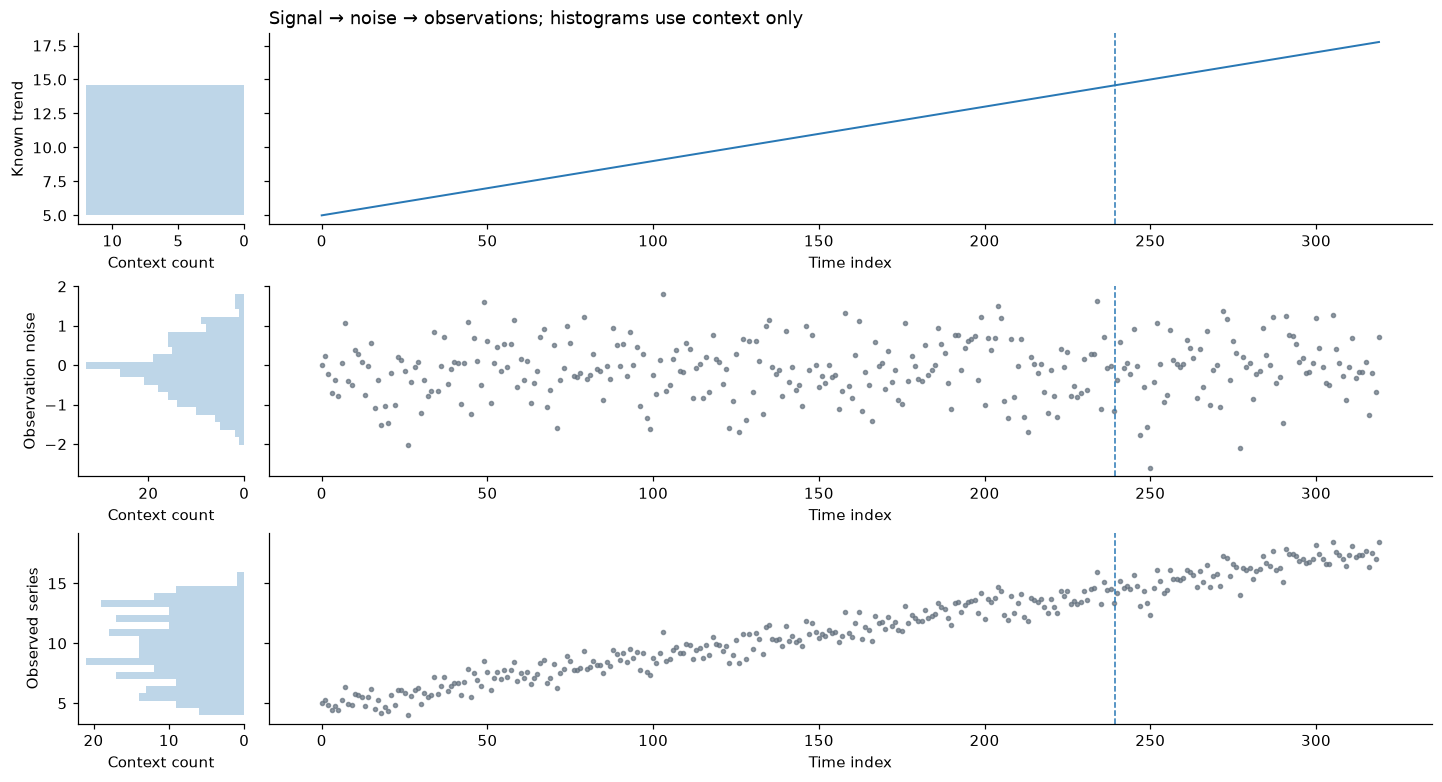

In [14]:
specification = Scenario('trend', context_length=240, horizon=80,
                         parameters={'intercept': 5., 'slope': .04, 'sigma': .8})
case = specification.generate(seed=7)
assert type(specification) is Scenario
assert type(case) is Case
values = pd.concat([case.task.context, case.observed])['y']
signal = 5. + .04 * values.index.to_numpy()
noise = values.to_numpy() - signal
fig, axes = plt.subplots(3, 2, figsize=(13, 7), width_ratios=[1, 7],
                         sharey='row', layout='constrained')
for row, (label, component, deterministic) in enumerate([
    ('Known trend', signal, True), ('Observation noise', noise, False),
    ('Observed series', values.to_numpy(), False)]):
    hist, ax = axes[row]
    hist.hist(component[:240], bins=20, orientation='horizontal', color='#2878b5', alpha=.3)
    hist.invert_xaxis()
    hist.set(ylabel=label, xlabel='Context count')
    hist.spines[['top', 'right']].set_visible(False)
    if deterministic:
        ax.plot(values.index, component, color='#2878b5', lw=1.3)
    else:
        ax.scatter(values.index, component, s=7, color='#64717e', alpha=.7)
    ax.axvline(239.5, color='#2878b5', ls='--', lw=1)
    ax.set_xlabel('Time index')
axes[0, 1].set_title('Signal → noise → observations; histograms use context only')
plt.show()
np.testing.assert_allclose(case.reference.mean[:, 0], signal[240:])

This decomposition is valid for a deterministic linear trend plus fresh white noise. The same principle applies to fixed sinusoidal seasonality plus white noise. A shock changes one observation; it does not move the future mean. A random walk **accumulates** shocks: each innovation changes the level inherited by subsequent steps. Its optional `drift` is a separate deterministic increment, zero by default. A zero-drift realization can still appear to trend over a finite window.

For AR(1) and random walks, the forecast reference conditions on the last observation; a realized future random path is not an oracle. White noise is independent over time here; multivariate targets may still have correlated shocks at the same time.


**Seasonality is not drift.** Seasonality repeats; process drift is an expected increment. A change in slope, seasonal amplitude/period/phase, or noise law is a change in the mechanism. A fixed seasonal cycle or fixed-parameter hidden regime process need not imply concept drift. See [controlled compositions and financial stresses](26_composed_and_financial_stresses.ipynb).

## See several draws together

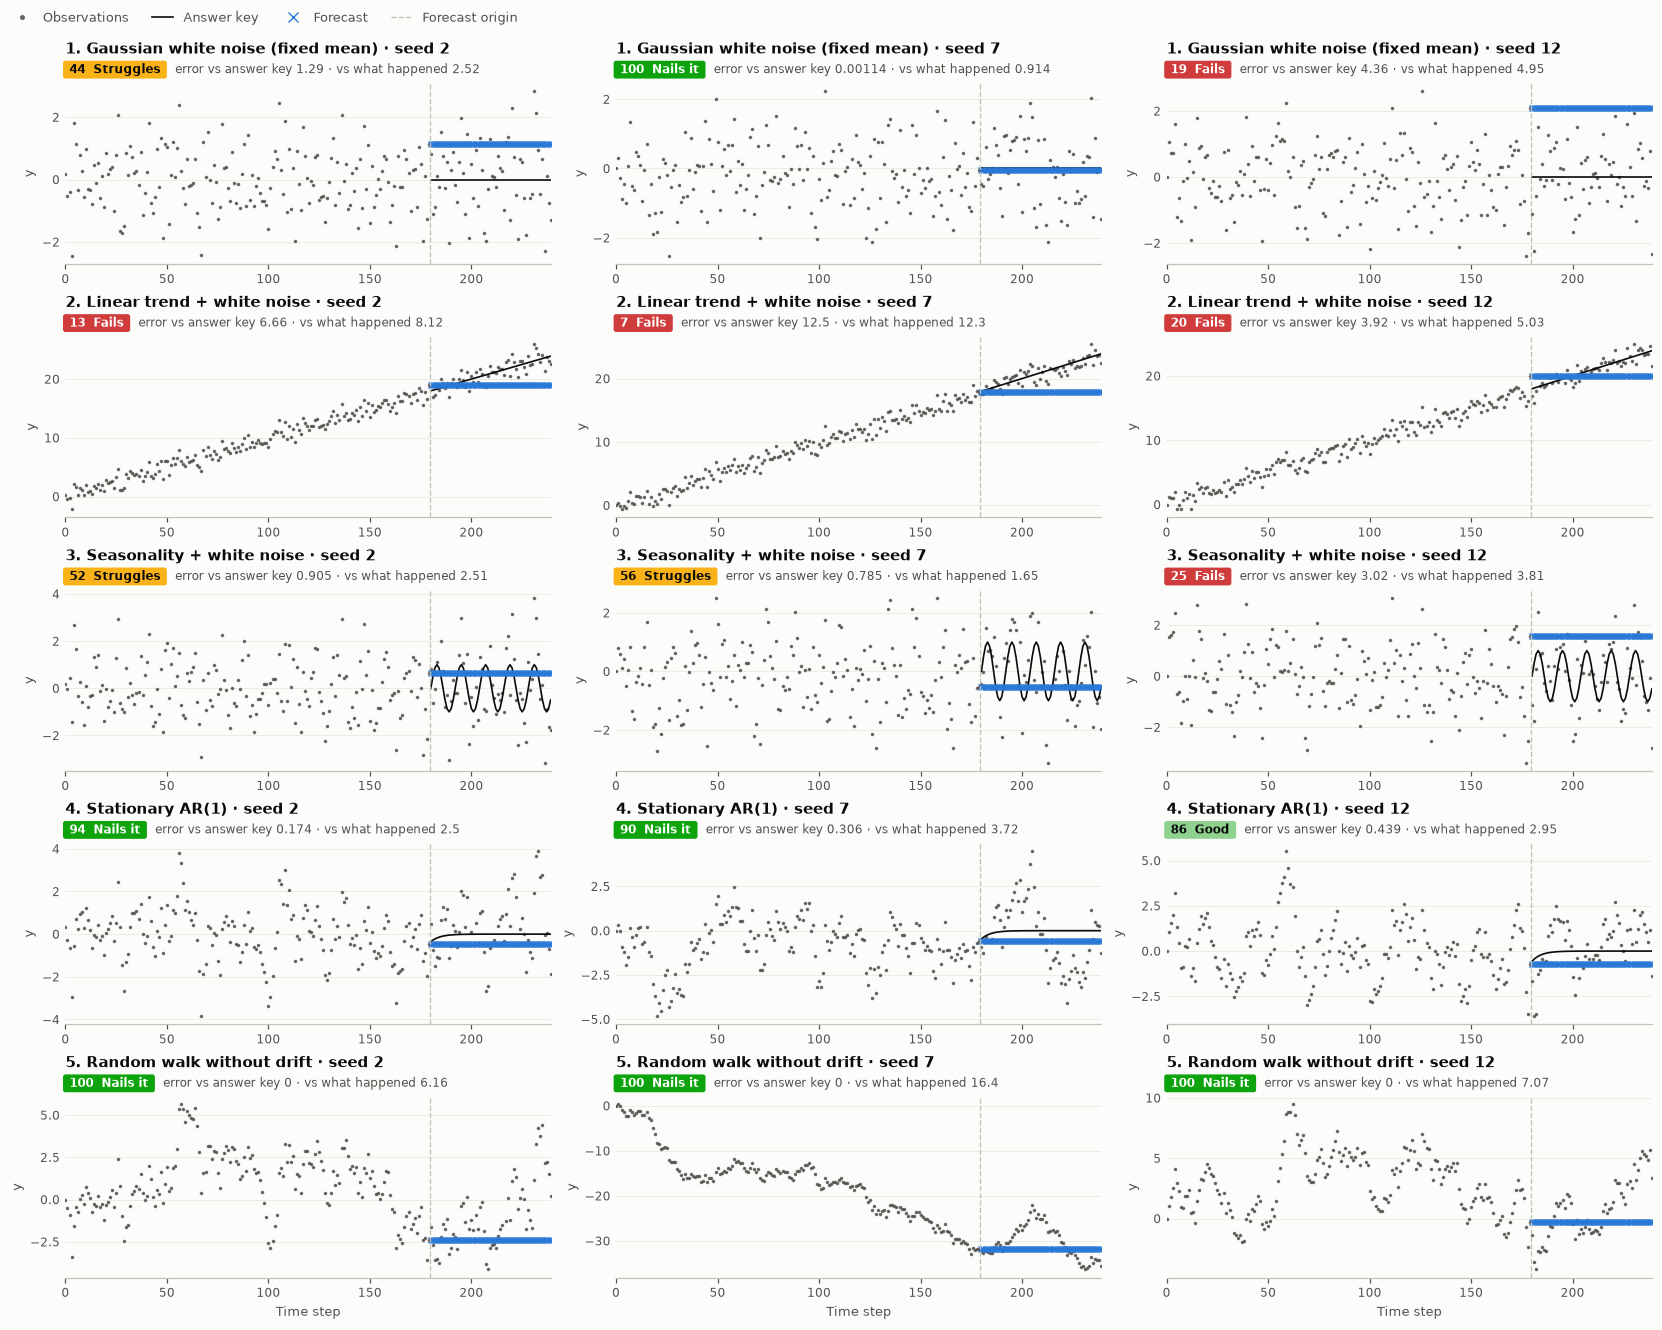

In [15]:
from timegym import Pipeline, NaiveForecaster
run = Pipeline(NaiveForecaster(strategy='last')).run(
    default_scenarios(context_length=180, horizon=60), seeds=[2, 7, 12])
assert all(type(entry.case) is Case for entry in run.cases)
run.plot_forecasts(figsize=(15, 12));
plt.show()

Rows hold the generating family fixed; columns change the seed. Blue crosses are point forecasts. Gray dots are stochastic observations. A correct forecast mean need not follow each realized shock.

## Edit, run, export

After editing a source cell, **restart this kernel and Run All**. This refreshes the local definitions, the development bindings between modules in this chapter, and the nearby examples. Ordinary Run All does not export files.

Changes to code owned by another chapter require saving that source notebook, running `python tools/export_notebooks.py`, and restarting this kernel before importing the updated package. Runtime provenance describes the exported package, not unexported edits.

Try one implementation or parameter change, rerun this chapter, and inspect the figure or assertion. Save the notebook before exporting.